## Data Analysis and Sampling

# Q1.0 Dataset Generation

## >  Install Dependencies 


In [1]:
import importlib
from IPython import get_ipython


dependencies = ["numpy", "pandas", "matplotlib", "seaborn", "scikit-learn"]

for pkg in dependencies:
    try:
        importlib.import_module(pkg)
        print(f"{pkg} already installed")
    except ImportError:
        print(f"{pkg} not found. Installing...")
        get_ipython().run_line_magic("pip", f"install {pkg}")


numpy already installed
pandas already installed
matplotlib already installed
seaborn already installed
scikit-learn not found. Installing...
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hashlib

print("All dependencies successfully imported")

All dependencies successfully imported


## > Personalized Random Seed

In [3]:
username = "gracy.garg"
seed = int ( hashlib . sha256 ( username . encode () ) . hexdigest () , 16)
seed = seed % (2**32)
print(f"Seed for {username}: {seed}")

Seed for gracy.garg: 1380115796


# > Include username in plots

In [4]:
def add_username_to_plot(username="gracy.garg"):
    """
    Adds the username to the top-right corner of the current plot.
    """
    plt.text(
        0.95, 0.95, username,
        ha='right', va='top',
        transform=plt.gca().transAxes,
        fontsize=10, color='gray', alpha=0.7
    )

## >Q1.0 Dataset Generation functions

In [5]:
class StudentDataset:
    def __init__ (self, num_students: int, seed: int):
        """Initialize StudentDataset with specified number of students and random seed."""
        self.num_students = num_students
        self.seed = seed
        self.rng = np.random.default_rng(seed) # creates a reproducible random number generator
        self.data = self.assemble_dataframe()

    def get_full_dataframe(self) -> pd.DataFrame:
        """Return the full DataFrame of student data"""
        return self.data

    def generate_gender(self) -> list[str]:
        """Generate gender with distribution: Male (65%), Female (33%), Other (2%)"""
        gender_choices = ['Male', 'Female', 'Other']
        gender_probabilities = [0.65, 0.33, 0.02]
        
        genders = self.rng.choice(
            gender_choices, 
            size=self.num_students, 
            p=gender_probabilities
        )
        return genders.tolist()


    def generate_major(self) -> list[str]:
        """Generate major with distribution: B.Tech (70%), MS (20%), PhD (10%)"""
        major_choices = ['B.Tech', 'MS', 'PhD']
        major_probabilities = [0.70, 0.20, 0.10]
        
        majors = self.rng.choice(
            major_choices, 
            size=self.num_students, 
            p=major_probabilities
        )
        return majors.tolist()
    
    def generate_program(self, majors: list[str]) -> list[str]:
        """Generate program choices based on major with conditional probabilities."""
        program_choices = ['CSE', 'ECE', 'CHD', 'CND']
        
        program_probabilities = {
            'B.Tech': [0.40, 0.40, 0.10, 0.10],
            'MS': [0.30, 0.30, 0.20, 0.20],
            'PhD': [0.25, 0.25, 0.25, 0.25]
        }
        
        programs = []
        for major in majors:                            # conditioning on major
            program = self.rng.choice(
                program_choices, 
                p=program_probabilities[major]
            )
            programs.append(program)
        
        return programs

    def generate_gpa(self, majors: list[str]) -> list[float]:
        """Generate GPA values based on major using normal distribution clipped to [4.0, 10.0]."""
        gpa_params = {
            'B.Tech': (7.0, 1.0),  
            'MS': (8.0, 0.7),
            'PhD': (8.3, 0.5)
        }
        
        gpas = []
        for major in majors:
            mean, std = gpa_params[major]
            gpa = self.rng.normal(mean, std)        # generate GPA on a normal distribution for given parameters (µ, σ)
            gpa = np.clip(gpa, 4.0, 10.0)           # restrict GPA to [4.0, 10.0]
            gpas.append(round(gpa, 2))              # round to 2 decimal places
        
        return gpas

    def assemble_dataframe(self) -> pd.DataFrame:
        """Create complete dataset by combining all generated student attributes."""
        genders = self.generate_gender()
        majors = self.generate_major()
        programs = self.generate_program(majors)
        gpas = self.generate_gpa(majors)
        
        df = pd.DataFrame({
            'gender': genders,
            'major': majors,
            'program': programs,
            'gpa': gpas
        })
        
        return df
    
    # ------------------------------------
    # def generate_data(self) -> pd.DataFrame:
    #     """Generate the full dataset of students"""
    #     df = self.assemble_dataframe()
    #     return df
    
    def gpa_mean_std(self)-> tuple[float, float]:
        """Calculate and return mean and standard deviation of GPA values."""
        mean = self.data["gpa"].mean()
        std = self.data["gpa"].std()
        return round(mean,2), round(std,2)

    def count_students_per_program_major_pair(self)-> pd.DataFrame:
        """Count number of students for each program-major combination."""
        counts = self.data.groupby(["program","major"]).size().reset_index(name="count")
        return counts

    def visualize_students_per_program_major_pair(self, counts_df):
        """Create heatmap visualization of student distribution across program-major pairs."""
        pivot = counts_df.pivot(index="program", columns="major", values="count")
        plt.figure(figsize=(8,6))
        sns.heatmap(pivot, annot=True, fmt="d", cmap="rocket")
        plt.title("Students per Program-Major Pair")
        add_username_to_plot()
        plt.show()



## > Call to generate data

In [6]:
dataset = StudentDataset(num_students=10000, seed=seed)

df = dataset.get_full_dataframe()
print("Dataset generated successfully with", len(df), "students.")

Dataset generated successfully with 10000 students.


# Q1.1 Dataset Analysis
## > (a) Visualizations

In [7]:
class StudentDataVisualizer:
    def __init__(self, data: pd.DataFrame, seed: int):
        """Initialize visualizer with student data and random seed."""
        self.data = data
        self.seed = seed

    def plot_gender_distribution(self):
        """Plot bar chart showing distribution of student genders with value labels."""
        plt.figure(figsize=(10,6))
        ax = sns.countplot(data=self.data, x="gender", hue="gender", palette="rocket", legend=False)
        plt.title("Gender Distribution")
        add_username_to_plot()
        plt.xlabel("Gender")
        plt.ylabel("Count")
        for p in ax.patches:
            ax.annotate(f'{int(p.get_height())}', 
                        (p.get_x() + p.get_width() / 2., p.get_height()), 
                        ha='center', va='bottom', fontsize=10)
        add_username_to_plot()
        plt.show()
    
    def plot_major_distribution(self):
        """Plot bar chart showing distribution of student majors with value labels."""
        plt.figure(figsize=(10,6))
        ax = sns.countplot(data=self.data, x="major", hue="major", palette="rocket", legend=False)
        plt.title("Major Distribution")
        add_username_to_plot()
        plt.xlabel("Major")
        plt.ylabel("Count")
        for p in ax.patches:
            ax.annotate(f'{int(p.get_height())}', 
                        (p.get_x() + p.get_width() / 2., p.get_height()), 
                        ha='center', va='bottom', fontsize=10)
        add_username_to_plot()
        plt.show()
    
    def plot_program_distribution(self):
        """Plot bar chart showing distribution of student programs with value labels."""
        plt.figure(figsize=(10,6))
        ax = sns.countplot(data=self.data, x="program", hue="program", palette="rocket", legend=False)
        plt.title("Program Distribution")
        add_username_to_plot()
        plt.xlabel("Program")
        plt.ylabel("Count")
        for p in ax.patches:
            ax.annotate(f'{int(p.get_height())}', 
                        (p.get_x() + p.get_width() / 2., p.get_height()), 
                        ha='center', va='bottom', fontsize=10)
        add_username_to_plot()
        plt.show()
    
    def plot_gpa_distribution(self, bins=20):
        """Plot histogram showing distribution of student GPAs with KDE overlay."""
        plt.figure(figsize=(10,6))
        ax = sns.histplot(self.data["gpa"], bins=bins, kde=True,color="purple")
        mean_gpa = self.data["gpa"].mean()
        plt.axvline(mean_gpa, color='black', linestyle='--', linewidth=2, label=f"Mean GPA: {mean_gpa:.2f}")
        plt.title("GPA Distribution")
        add_username_to_plot()
        plt.xlabel("GPA")
        plt.ylabel("Frequency")
        ylim = ax.get_ylim()[1]
        for p in ax.patches:
            height = int(p.get_height())
            if height > 0:
                ax.annotate(
                    f'{height}',
                    (p.get_x() + p.get_width() / 2., height + 0.01 * ylim),
                    ha='center', va='bottom', fontsize=9
                )
        plt.legend()
        add_username_to_plot()
        plt.tight_layout()
        plt.show()
        
    def plot_program_by_major(self):
        """Plot grouped bar chart showing program distribution within each major."""
        plt.figure(figsize=(10,6))
        sns.countplot(data=self.data, x="major", hue="program", palette="rocket",legend=True)
        plt.title("Program Distribution by Major")
        add_username_to_plot()
        plt.xlabel("Major")
        plt.ylabel("Count")
        plt.legend(title="Program")
        add_username_to_plot()
        plt.show()
    
    def plot_gpa_by_major(self):
        """Plot box plot showing GPA distribution for each major."""
        plt.figure(figsize=(10,6))
        sns.boxplot(data=self.data, x="major", y="gpa", hue="major", palette="rocket", legend=False)
        plt.title("GPA by Major")
        add_username_to_plot()
        plt.show()
    
    def plot_gpa_by_program(self):
        """Plot box plot showing GPA distribution for each program."""
        plt.figure(figsize=(10,6))
        sns.boxplot(data=self.data, x="program", y="gpa", hue="program", palette="rocket", legend=False)
        plt.title("GPA by Program")
        add_username_to_plot()
        plt.show()
    
    def plot_gpa_by_program_and_major(self):
        """Plot box plot showing GPA distribution by program with major as hue."""
        plt.figure(figsize=(10,6))
        sns.boxplot(data=self.data, x="program", y="gpa", hue="major", palette="rocket")
        plt.title("GPA by Program and Major")
        add_username_to_plot()
        plt.show()
    
    def plot_sampled_dataset(self, n=100):
        """Visualize sampled dataset using multiple informative plots."""
        sample = self.data.sample(n=n, random_state=self.seed)
        fig, axs = plt.subplots(2, 2, figsize=(10, 6))
        
        sns.countplot(data=sample, x="gender", ax=axs[0, 0], hue="gender", palette="rocket")
        axs[0, 0].set_title("Gender Distribution (Sample)")
        axs[0, 0].set_xlabel("Gender")
        axs[0, 0].set_ylabel("Count")
        
        sns.countplot(data=sample, x="major", ax=axs[0, 1], hue="major", palette="rocket")
        axs[0, 1].set_title("Major Distribution (Sample)")
        axs[0, 1].set_xlabel("Major")
        axs[0, 1].set_ylabel("Count")
        
        sns.histplot(sample["gpa"], bins=10, kde=True, ax=axs[1, 0], color="purple")
        axs[1, 0].set_title("GPA Distribution (Sample)")
        axs[1, 0].set_xlabel("GPA")
        axs[1, 0].set_ylabel("Frequency")

        sns.boxplot(data=sample, x="program", y="gpa", ax=axs[1, 1], hue="program", palette="rocket")
        axs[1, 1].set_title("GPA by Program (Sample)")
        axs[1, 1].set_xlabel("Program")
        axs[1, 1].set_ylabel("GPA")
        
        plt.tight_layout()
        add_username_to_plot()
        plt.show()

    def plot_entire_dataset_summary(self):
        """Dashboard with integrated plots in a 3x3 grid."""
        sns.set_theme(style="whitegrid")
        fig, axes = plt.subplots(3, 3, figsize=(20, 12))
        axes = axes.flatten()

        # Gender Distribution
        sns.countplot(data=self.data, x="gender", hue="gender", palette="rocket", ax=axes[0])
        axes[0].set_title("Gender Distribution")
        for p in axes[0].patches:
            height = p.get_height()
            axes[0].annotate(f'{height}', (p.get_x() + p.get_width() / 2., height),
                            ha='center', va='bottom', fontsize=9)

        # Major Distribution
        sns.countplot(data=self.data, x="major", hue="major", palette="rocket", ax=axes[1])
        axes[1].set_title("Major Distribution")
        for p in axes[1].patches:
            height = p.get_height()
            axes[1].annotate(f'{height}', (p.get_x() + p.get_width() / 2., height),
                            ha='center', va='bottom', fontsize=9)

        # Program Distribution
        sns.countplot(data=self.data, x="program", hue="program", palette="rocket", ax=axes[2])
        add_username_to_plot()
        axes[2].set_title("Program Distribution")
        for p in axes[2].patches:
            height = p.get_height()
            axes[2].annotate(f'{height}', (p.get_x() + p.get_width() / 2., height),
                            ha='center', va='bottom', fontsize=9)

        # GPA Distribution
        mean_gpa = self.data["gpa"].mean()
        sns.histplot(self.data["gpa"], bins=20, kde=True, color="purple", ax=axes[3])
        axes[3].axvline(mean_gpa, color='black', linestyle='--', linewidth=2,
                        label=f"Mean GPA: {mean_gpa:.2f}")
        axes[3].set_title("GPA Distribution")
        axes[3].legend()

        # GPA by Major
        sns.boxplot(data=self.data, x="major", y="gpa", hue="major", legend=False, palette="rocket", ax=axes[4])
        axes[4].set_title("GPA by Major")

        # GPA by Program
        sns.boxplot(data=self.data, x="program", y="gpa", hue="program", legend=False, palette="rocket", ax=axes[5])
        axes[5].set_title("GPA by Program")

        # Correlation Heatmap
        encoded = self.data.copy()
        encoded['Gender'] = encoded['gender'].astype('category').cat.codes
        encoded['Major'] = encoded['major'].astype('category').cat.codes
        encoded['Program'] = encoded['program'].astype('category').cat.codes
        corr = encoded[['Gender', 'Major', 'Program', 'gpa']].corr()

        sns.heatmap(corr, annot=True, cmap="rocket", fmt=".2f", ax=axes[6])
        axes[6].set_title("Feature Correlation Heatmap")

        # Major vs Program Crosstab
        cross_tab = pd.crosstab(self.data['major'], self.data['program'])
        cross_tab.plot(kind="bar", stacked=True, ax=axes[7], colormap="rocket", legend=False)
        axes[7].set_title("Major vs Program Distribution")

        for container in axes[7].containers:
            axes[7].bar_label(container, label_type='center', fontsize=8)

        # GPA Density by Program (KDE Plot)
        sns.kdeplot(data=self.data, x="gpa", hue="program", fill=True, palette="rocket", ax=axes[8])
        axes[8].set_title("GPA Density by Program")

        # Final Layout and Title
        fig.suptitle("Student Dataset Dashboard", fontsize=18, fontweight="bold", y=1.02)
        plt.tight_layout()
        plt.show()



## > Plot All Graphs


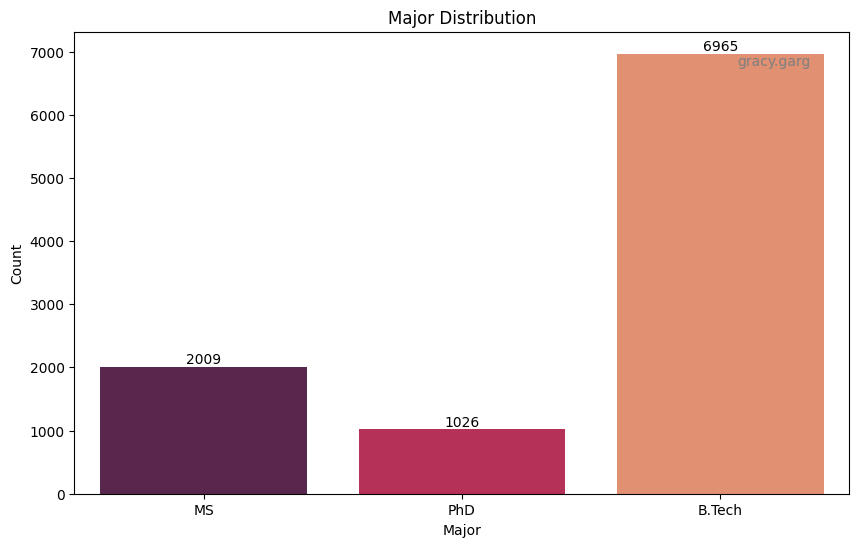

In [8]:
plotter = StudentDataVisualizer(data=df, seed=seed)
plotter.plot_major_distribution()

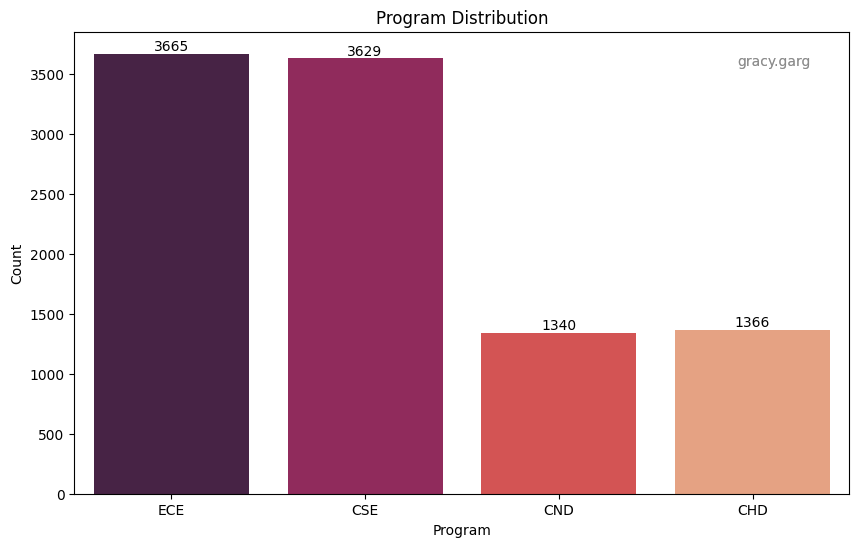

In [9]:
plotter.plot_program_distribution()

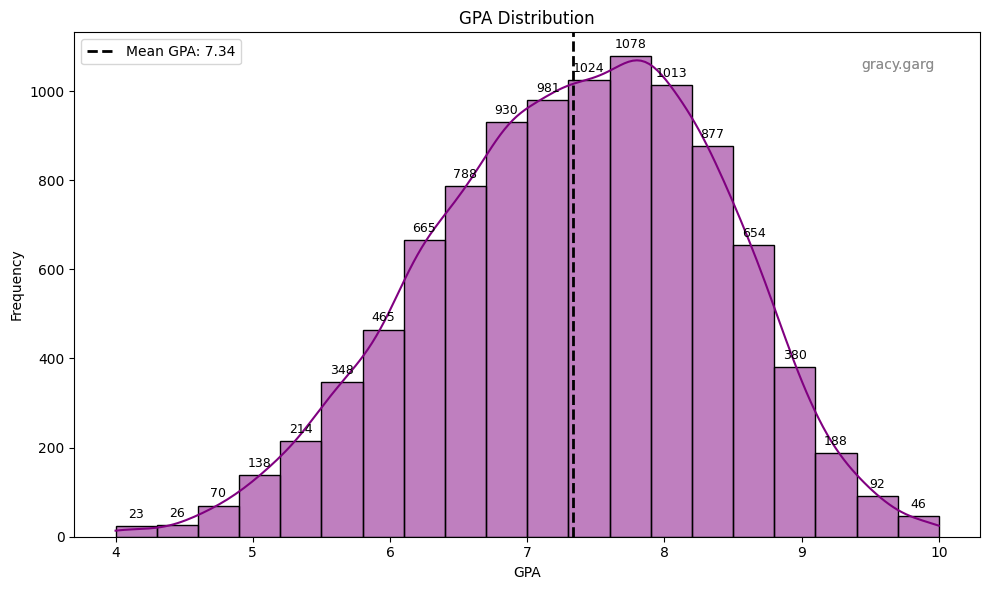

In [10]:
plotter.plot_gpa_distribution()

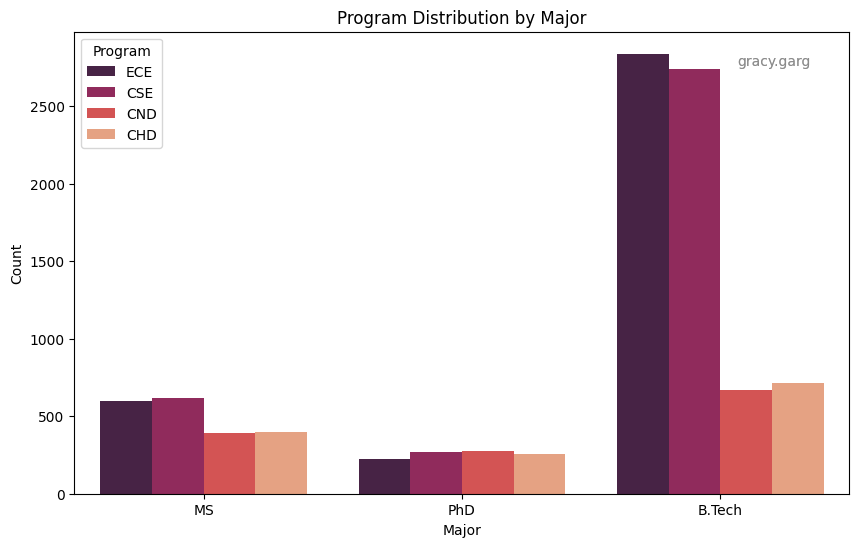

In [11]:

plotter.plot_program_by_major()

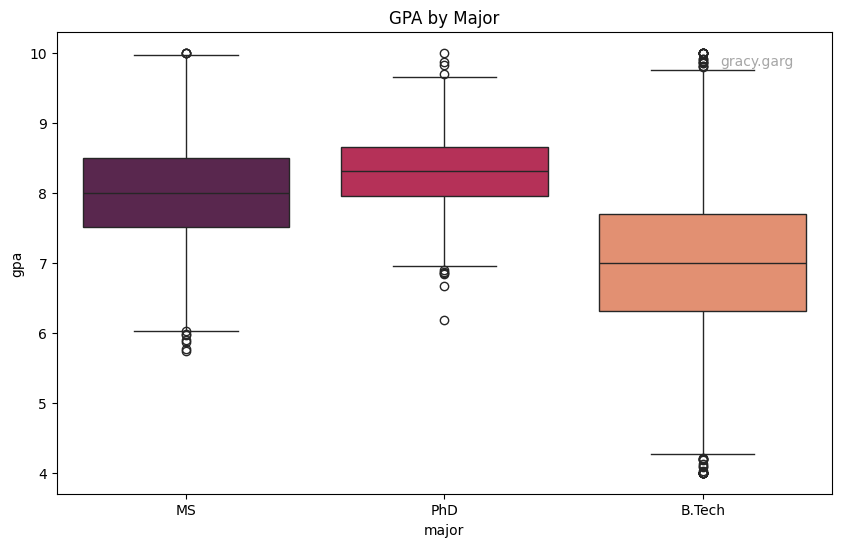

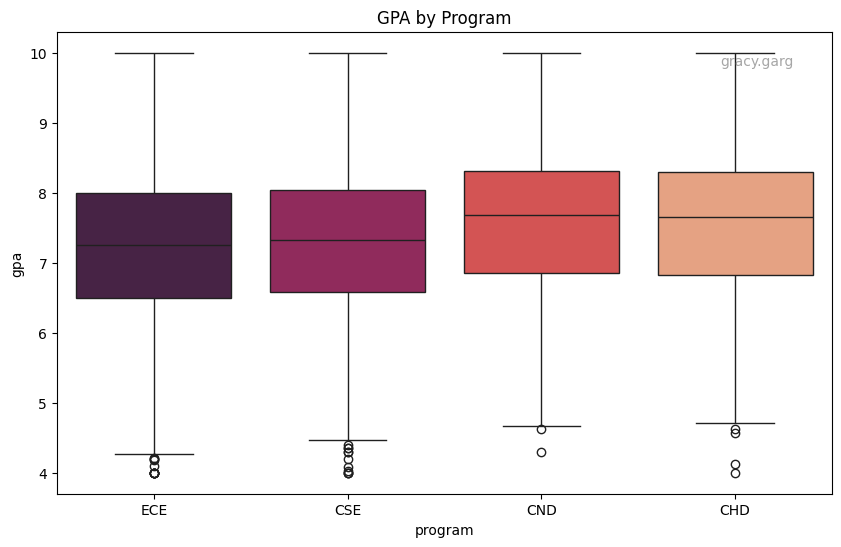

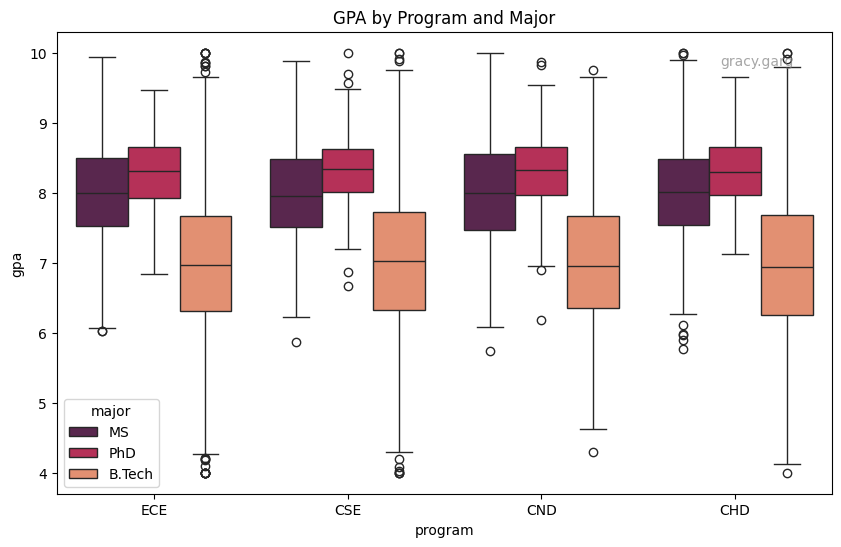

In [12]:
plotter.plot_gpa_by_major()
plotter.plot_gpa_by_program()
plotter.plot_gpa_by_program_and_major()

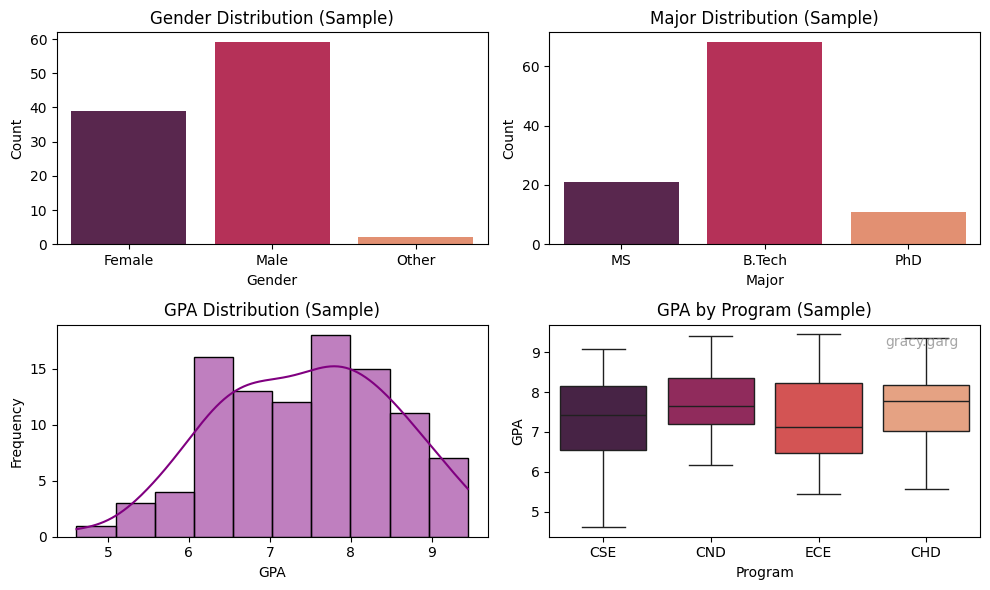

In [13]:
plotter.plot_sampled_dataset()


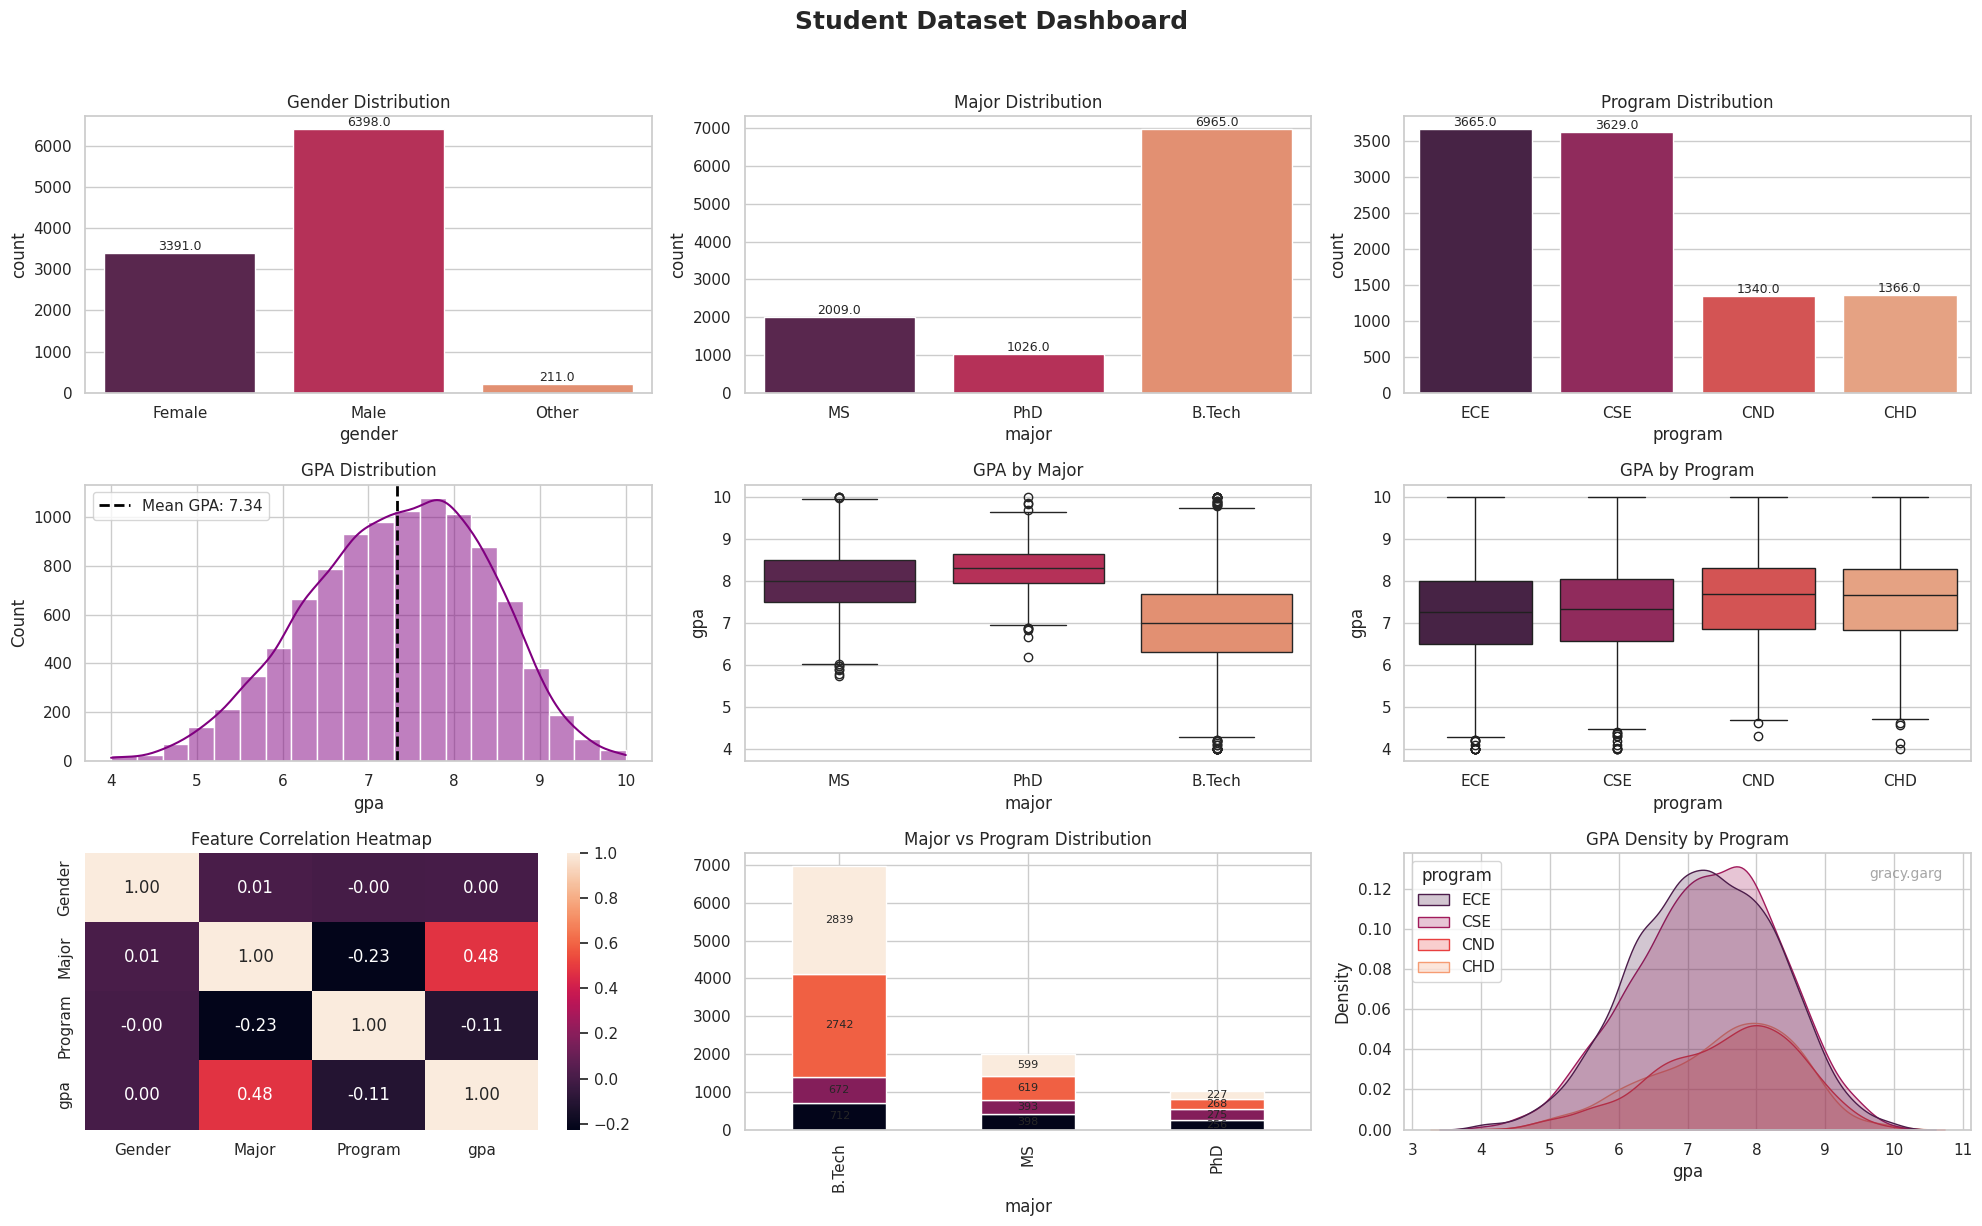

In [14]:
plotter.plot_entire_dataset_summary()

## > (b) GPA Summary Statistics

In [15]:

mean, std = dataset.gpa_mean_std()
print("Mean GPA:", mean, " | Std Dev:", std)


Mean GPA: 7.34  | Std Dev: 1.05


**Observation:**  
The theoretical expected mean GPA is ~7.3 (weighted by major distribution).  
μ=(0.7 * 7.0)+(0.2 * 8.0)+(0.1 * 8.3)  
μ=4.9+1.6+0.83=7.33

<!-- My generated dataset shows ~7.7–7.8, which is slightly higher because: -->
This is consistent with the observed value, this is because
- The largest group (B.Tech, 70%) already has mean GPA 7 so it is more close to this value.
- MS and PhD students have higher GPAs with less variance, pulling the mean slightly more than 7.  
<!-- - GPA values are clipped at [4,10], reducing the effect of very low B.Tech GPAs.   -->
<!-- Thus, the result is consistent with the underlying distributions. -->

<!-- Commenting out this line 'gpa = np.clip(gpa, 4.0, 10.0)' will give the expected mean ~7.3-7.4 -->

The overall GPA standard deviation is ~1.0.  
This matches expectations because:
- The largest group (B.Tech, 70%) already has σ ≈ 1.0.  
- MS and PhD groups are smaller and have tighter GPA distributions, so they do not add much additional spread.  
<!-- - Although inter-group differences (7.0 vs 8.0 vs 8.3) increase variance, clipping GPAs to [4,10] reduces extreme low values, balancing the effect.   -->
Thus, the dataset’s overall spread remains close to 1.0, which is consistent with the specified distributions.



## > (c) Program-Major Combinations

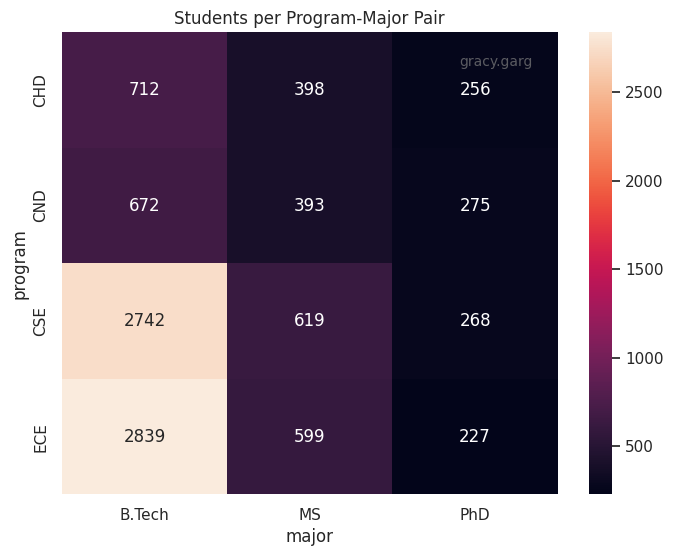

In [16]:

counts_df = dataset.count_students_per_program_major_pair()
dataset.visualize_students_per_program_major_pair(counts_df)

**Observation:**  
The heatmap shows the distribution of students across program & major combinations.  
The distribution of students across (program, major) combinations generally follows the specified probabilities defined in Q1.0:

- **B.Tech students dominate** the dataset, especially in CSE (≈2800) and ECE (≈2800). This matches the 70% prior for B.Tech and the 40% probability of choosing CSE/ECE for B.Tech students.  
- **MS students** are much fewer (20% total), and they are relatively balanced between CSE (≈600), ECE (≈600), CHD (≈400), and CND (≈400). This matches the 30/30/20/20 distribution specified.  
- **PhD students** are the smallest group (10% total), and they are spread almost evenly across programs (≈250 each), consistent with their 25/25/25/25 distribution.  
- **CHD and CND are minority programs** among B.Tech students (≈700 each) but have relatively stronger representation in MS and PhD cohorts (since their probabilities are higher there).  


# Q1.2 Simple vs Stratified Sampling

In [17]:
class StudentAnalysis:
    def __init__(self, data: pd.DataFrame, seed: int):
        """Initialize analysis class with student data and random seed."""
        self.data = data
        self.seed = seed
        self.rng = np.random.default_rng(seed)

    def get_gpa_mean_std_random(self, n=500, repeats=50):
        """Calculate mean and std of GPA estimates using simple random sampling."""
        means = []
        for _ in range(repeats):
            sample = self.data.sample(n=n, random_state=self.rng.integers(1e9))
            means.append(sample['gpa'].mean()) 
        return round(np.mean(means),2), round(np.std(means),2)

    def get_gpa_mean_std_stratified(self, n=500, repeats=50):   
        """Calculate mean and std of GPA estimates using stratified sampling by major."""
        majors = self.data['major'].unique()
        major_counts = self.data['major'].value_counts(normalize=True)

        means = []
        for _ in range(repeats):
            sample_parts = []
            for m in majors:
                size = int(round(n * major_counts[m]))
                subset = self.data[self.data['major'] == m].sample(size, random_state=self.rng.integers(1e9))
                sample_parts.append(subset)
            sample = pd.concat(sample_parts)
            means.append(sample['gpa'].mean()) 
        return round(np.mean(means),2), round(np.std(means),2)

In [18]:
analysis = StudentAnalysis(data=df, seed=seed)
mean_r, std_r = analysis.get_gpa_mean_std_random()
mean_s, std_s = analysis.get_gpa_mean_std_stratified()

print(f"Random Sampling:\n      Mean GPA = {mean_r:.2f}\n      Std Dev = {std_r:.2f}")
print(f"Stratified Sampling:\n      Mean GPA = {mean_s:.2f}\n      Std Dev = {std_s:.2f}")

Random Sampling:
      Mean GPA = 7.32
      Std Dev = 0.05
Stratified Sampling:
      Mean GPA = 7.33
      Std Dev = 0.04


Stratified sampling has a lower standard deviation (0.04) compared to random sampling (0.05). This is because stratified sampling divides the population into homogeneous subgroups (e.g., by major) and samples proportionally from each, reducing variability and ensuring each subgroup is well-represented. In contrast, random sampling can lead to over or under representation of certain groups, causing higher variability in the sample’s GPA estimate.

# Q1.3 Gender-Balanced Cohort

In [19]:
class AdvStudentAnalysis(StudentAnalysis):
    # Q1.3 Methods
    def get_gender_balanced_counts(self, n: int = 300, repeats: int = 5) -> list[dict[str, int]]:
        """ Sample students by gender with exact same count across genders """
        genders = self.data["gender"].unique()
        k = len(genders)
        size_per_gender = n // k            # integer division

        results = []
        for _ in range(repeats):
            parts = []
            for g in genders:
                subset = self.data[self.data["gender"] == g]
                take = subset.sample(n=size_per_gender, random_state=int(self.rng.integers(1e9)))
                parts.append(take)
            sample = pd.concat(parts)
            results.append(sample["gender"].value_counts().to_dict())
        return results


    # Strategy A: sample gender uniformly, then pick a student from that gender
    def sample_gender_uniform_random(self, n: int = 300, repeats: int = 5) -> list[dict[str, int]]:
        """Sample students by gender using strategy A:"""
        genders = self.data["gender"].unique()
        results = []

        for _ in range(repeats):
            chosen_genders = self.rng.choice(genders, size=n)
            gender_counts = pd.Series(chosen_genders).value_counts()
            parts = []
            for gender, count in gender_counts.items():
                subset = self.data[self.data["gender"] == gender]
                actual_count = min(count, len(subset))
                sampled = subset.sample(n=actual_count, random_state=self.rng.integers(1e9))
                parts.append(sampled)
            
            sample = pd.concat(parts, ignore_index=True)
            results.append(sample["gender"].value_counts().to_dict())
        return results


    def plot_avg_max_gender_diff_vs_sample_size(self, sample_sizes: list[int], repeats: int = 10) -> None:
        """
        Plot gender imbalance vs sample size under Strategy A.
        """
        genders = self.data["gender"].unique()
        avg_diffs = []

        for n in sample_sizes:
            diffs = []
            for _ in range(repeats):
                chosen_genders = self.rng.choice(genders, size=n)
                gender_counts = pd.Series(chosen_genders).value_counts()
                full_counts = pd.Series(0, index=genders)   # fill in missing
                full_counts.update(gender_counts)
                
                counts = full_counts.values
                diff = (max(counts) - min(counts)) / n
                diffs.append(diff)
            avg_diffs.append(np.mean(diffs))

        summary_df = pd.DataFrame({
            "Sample Size": sample_sizes,
            "Avg Max Relative Difference": [round(d, 4) for d in avg_diffs]
        })
        display(summary_df)
        plt.figure(figsize=(10,6))
        ax = sns.barplot(x=sample_sizes, y=avg_diffs, hue=sample_sizes, palette="Greens", legend=False)
        plt.xlabel("Sample Size (n)")
        plt.ylabel("Average Max Relative Difference")
        plt.title("Gender Imbalance under Strategy A")
        for i, v in enumerate(avg_diffs):
            ax.text(i, v, f"{v:.3f}", ha='center', va='bottom', fontsize=10)
        add_username_to_plot()
        plt.show()


    # Q1.4 Methods
    def sample_gpa_uniform(self, n: int = 100, bins: int = 10) -> pd.DataFrame:
        """
        Sample students using Strategy A applied to GPA bins
        Using sampling without replacement to avoid duplicates and ensure diverse selection.
        """
        gpa_min, gpa_max = self.data['gpa'].min(), self.data['gpa'].max()
        bin_edges = np.linspace(gpa_min, gpa_max, bins + 1)
        
        # Create bin labels for each student
        bin_labels = []
        for i in range(bins):
            lower = bin_edges[i]
            upper = bin_edges[i + 1]
            if i == bins - 1:
                bin_data = self.data[(self.data['gpa'] >= lower) & (self.data['gpa'] <= upper)]
            else:
                bin_data = self.data[(self.data['gpa'] >= lower) & (self.data['gpa'] < upper)]
            
            if len(bin_data) > 0:  # Only include bins that have students
                bin_labels.append(i)
        
        sampled_parts = []
        
        # Strategy A
        for _ in range(n):
            chosen_bin = self.rng.choice(bin_labels)
            lower = bin_edges[chosen_bin]
            upper = bin_edges[chosen_bin + 1]
            
            if chosen_bin == bins - 1:
                bin_data = self.data[(self.data['gpa'] >= lower) & (self.data['gpa'] <= upper)]
            else:
                bin_data = self.data[(self.data['gpa'] >= lower) & (self.data['gpa'] < upper)]
            
            if len(bin_data) > 0:
                sampled_student = bin_data.sample(n=1, random_state=self.rng.integers(1e9))
                sampled_parts.append(sampled_student)
                self.data = self.data.drop(sampled_student.index)
        
        result = pd.concat(sampled_parts, ignore_index=True)
        display(f"Sampled {len(result)} students using Strategy A across {bins} GPA bins")
        
        bin_counts = {}
        for i in range(bins):
            lower = bin_edges[i]
            upper = bin_edges[i + 1]
            if i == bins - 1:
                count = len(result[(result['gpa'] >= lower) & (result['gpa'] <= upper)])
            else:
                count = len(result[(result['gpa'] >= lower) & (result['gpa'] < upper)])
            bin_counts[f"Bin {i+1} [{lower:.2f}-{upper:.2f}]"] = count
        
        bin_counts_df = pd.DataFrame(list(bin_counts.items()), columns=["GPA Bin", "Count"])
        display(bin_counts_df)
        return result
 

    def plot_gpa_histogram_comparison(self, sampled_df: pd.DataFrame) -> None:
        """
        Plot GPA histogram comparison between original dataset and sampled data.
        """
        orig_gpa = self.data['gpa']
        samp_gpa = sampled_df['gpa']
        orig_mean = orig_gpa.mean()
        samp_mean = samp_gpa.mean()

        fig, axes = plt.subplots(1, 2, figsize=(22, 5))

        axes[0].hist(orig_gpa, bins=10, alpha=0.7, color='pink', edgecolor='black')
        axes[0].axvline(orig_mean, color='blue', linestyle='--', linewidth=2, label=f"Mean: {orig_mean:.2f}")
        axes[0].set_title('Original Dataset GPA Distribution')
        axes[0].set_xlabel('GPA')
        axes[0].set_ylabel('Frequency')
        axes[0].grid(True, alpha=0.3)
        axes[0].legend()

        axes[1].hist(samp_gpa, bins=10, alpha=0.7, color='purple', edgecolor='black')
        axes[1].axvline(samp_mean, color='red', linestyle='--', linewidth=2, label=f"Mean: {samp_mean:.2f}")
        axes[1].set_title('Sampled Dataset GPA Distribution\n(Uniform Sampling)')
        axes[1].set_xlabel('GPA')
        axes[1].set_ylabel('Frequency')
        axes[1].grid(True, alpha=0.3)
        axes[1].legend()

        plt.tight_layout()
        add_username_to_plot()
        plt.show()

        print(f"Original Dataset - Mean: {orig_mean:.2f}, Std: {orig_gpa.std():.2f}")
        print(f"Sampled Dataset  - Mean: {samp_mean:.2f}, Std: {samp_gpa.std():.2f}")


    # Q1.5 Methods 
    def sample_program_major_balanced(self, n: int = 60) -> pd.DataFrame:
        """
        Sample students using Strategy A applied to (program, major) combinations: 
        Uses sampling without replacement.
        """

        # Get all unique program-major combinations
        combinations = self.data.groupby(['program', 'major']).size().reset_index(name='available_count')
        valid_combinations = combinations[combinations['available_count'] > 0]
        
        print(f"Found {len(valid_combinations)} valid (program, major) combinations:")
        display(valid_combinations)
        
        combo_labels = []
        for _, row in valid_combinations.iterrows():
            combo_labels.append((row['program'], row['major']))
        
        sampled_parts = []
        
        # Strategy A
        for _ in range(n):
            chosen_combo = self.rng.choice(len(combo_labels))
            chosen_program, chosen_major = combo_labels[chosen_combo]            
            combo_data = self.data[(self.data['program'] == chosen_program) & 
                                (self.data['major'] == chosen_major)]
            
            if len(combo_data) > 0:
                sampled_student = combo_data.sample(n=1, random_state=self.rng.integers(1e9))
                sampled_parts.append(sampled_student)
                self.data = self.data.drop(sampled_student.index)
            else:
                print(f"Warning: No students available for {chosen_program}-{chosen_major}")
        
        result = pd.concat(sampled_parts, ignore_index=True)
        print(f"\nSampled {len(result)} students using Strategy A")
        
        combo_counts = {}
        for program, major in combo_labels:
            count = len(result[(result['program'] == program) & (result['major'] == major)])
            combo_counts[f"{program}-{major}"] = count
        
        # Tabularise the program-major combination distribution in sample
        combo_counts_df = pd.DataFrame(
            list(combo_counts.items()), columns=["Program-Major Combination", "Count"]
        )
        print("Program-Major combination distribution in sample:")
        display(combo_counts_df)
        
        return result

    def show_program_major_counts_and_heatmap(self, sampled_df: pd.DataFrame) -> None:
        """
        Show counts table and heatmap for program-major combinations in sampled data.
        """

        sampled_counts = sampled_df.groupby(['program', 'major']).size().reset_index(name='sampled_count')
        original_counts = self.data.groupby(['program', 'major']).size().reset_index(name='original_count')
        comparison = pd.merge(original_counts, sampled_counts, on=['program', 'major'], how='left')
        comparison['sampled_count'] = comparison['sampled_count'].fillna(0).astype(int)
        
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
        
        original_pivot = self.data.groupby(['program', 'major']).size().unstack(fill_value=0)
        sns.heatmap(original_pivot, annot=True, fmt='d', cmap='Blues', ax=ax1)
        ax1.set_title('Original Dataset\nProgram-Major Distribution')
        
        sampled_pivot = sampled_df.groupby(['program', 'major']).size().unstack(fill_value=0)
        sns.heatmap(sampled_pivot, annot=True, fmt='d', cmap='Reds', ax=ax2)
        ax2.set_title('Sampled Dataset\nProgram-Major Distribution')
        
        plt.tight_layout()
        add_username_to_plot()
        plt.show()


In [20]:
advanced_analysis = AdvStudentAnalysis(data=df, seed=seed)
balanced_counts = advanced_analysis.get_gender_balanced_counts()

print("Gender-Balanced Sampling Results:")
print("=" * 50)

balanced_df = pd.DataFrame(balanced_counts)
balanced_df.index = [f"Sample {i+1}" for i in range(len(balanced_counts))]
display(balanced_df.style.set_properties(**{'font-size': '16px'}))

print("\nSummary Statistics:")
print("-" * 30)
for gender in balanced_df.columns:
    mean_count = balanced_df[gender].mean()
    std_count = balanced_df[gender].std()
    print(f"{gender:7}: {mean_count:5.1f} ± {std_count:4.1f}")


Gender-Balanced Sampling Results:


,Female,Male,Other
Sample 1,100,100,100
Sample 2,100,100,100
Sample 3,100,100,100
Sample 4,100,100,100
Sample 5,100,100,100



Summary Statistics:
------------------------------
Female : 100.0 ±  0.0
Male   : 100.0 ±  0.0
Other  : 100.0 ±  0.0


In [21]:
strategyA_counts = advanced_analysis.sample_gender_uniform_random()

print("\nStrategy A (Uniform Random Gender Selection) Results:")
print("=" * 60)

strategyA_df = pd.DataFrame(strategyA_counts)
strategyA_df.index = [f"Sample {i+1}" for i in range(len(strategyA_counts))]
display(strategyA_df.style.set_properties(**{'font-size': '16px'}))

print("\nSummary Statistics:")
print("-" * 30)
for gender in strategyA_df.columns:
    mean_count = strategyA_df[gender].mean()
    std_count = strategyA_df[gender].std()
    print(f"{gender:7}: {mean_count:5.1f} ± {std_count:4.1f}")



Strategy A (Uniform Random Gender Selection) Results:


,Male,Other,Female
Sample 1,102,101,97
Sample 2,90,112,98
Sample 3,102,107,91
Sample 4,104,96,100
Sample 5,105,91,104



Summary Statistics:
------------------------------
Male   : 100.6 ±  6.1
Other  : 101.4 ±  8.4
Female :  98.0 ±  4.7


,Sample Size,Avg Max Relative Difference
0,300,0.0557
1,600,0.0483
2,900,0.0400
3,1200,0.0328
4,1500,0.0219


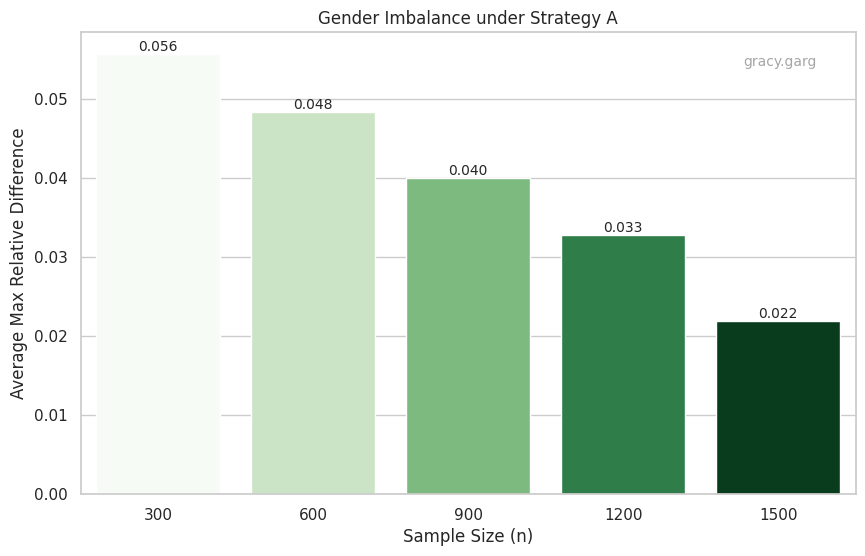

In [22]:
advanced_analysis.plot_avg_max_gender_diff_vs_sample_size([300, 600, 900, 1200, 1500])


# Q1.4 GPA-Uniform Cohort

In [23]:
# Q1.4: Sample 100 students with approximately uniform GPA distribution
gpa_uniform_sample_df = advanced_analysis.sample_gpa_uniform(n=100, bins=10)


'Sampled 100 students using Strategy A across 10 GPA bins'

,GPA Bin,Count
0,Bin 1 [4.00-4.60],14
1,Bin 2 [4.60-5.20],12
2,Bin 3 [5.20-5.80],10
3,Bin 4 [5.80-6.40],11
4,Bin 5 [6.40-7.00],11
5,Bin 6 [7.00-7.60],7
6,Bin 7 [7.60-8.20],7
7,Bin 8 [8.20-8.80],10
8,Bin 9 [8.80-9.40],7
9,Bin 10 [9.40-10.00],11


Sampling Strategy: Without replacement   
Reason: It ensures:
 1. No duplicate students in the sample
 2. More diverse representation across GPA ranges
 3. Better approximation of uniform distribution
 4. Avoids bias from repeated selection of same students

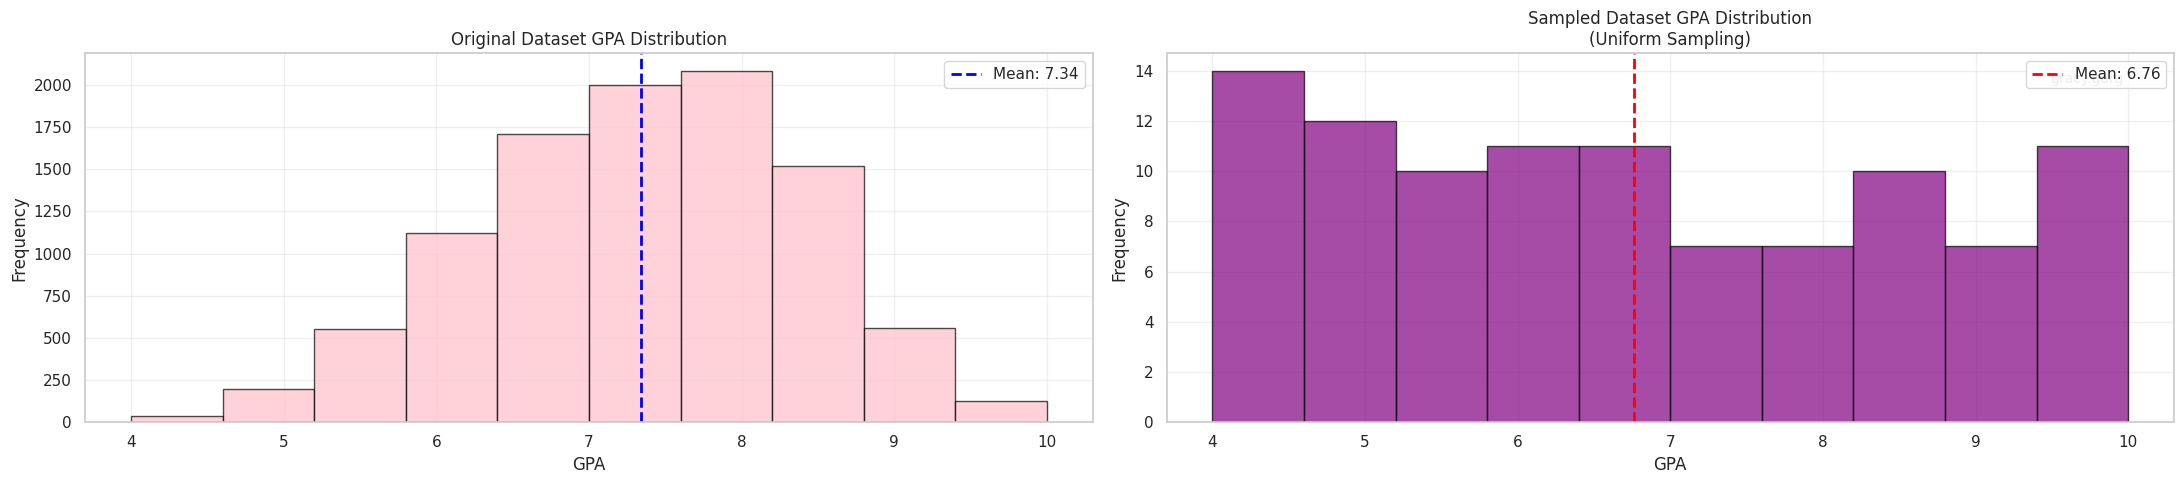

Original Dataset - Mean: 7.34, Std: 1.04
Sampled Dataset  - Mean: 6.76, Std: 1.77


In [24]:

advanced_analysis.plot_gpa_histogram_comparison(gpa_uniform_sample_df)

# Q1.5 Program-Major Balanced Cohort

Found 12 valid (program, major) combinations:


,program,major,available_count
0,CHD,B.Tech,699
1,CHD,MS,396
2,CHD,PhD,256
3,CND,B.Tech,663
4,CND,MS,390
5,CND,PhD,274
6,CSE,B.Tech,2711
7,CSE,MS,612
8,CSE,PhD,267
9,ECE,B.Tech,2810



Sampled 60 students using Strategy A
Program-Major combination distribution in sample:


,Program-Major Combination,Count
0,CHD-B.Tech,4
1,CHD-MS,7
2,CHD-PhD,8
3,CND-B.Tech,2
4,CND-MS,7
5,CND-PhD,4
6,CSE-B.Tech,2
7,CSE-MS,7
8,CSE-PhD,5
9,ECE-B.Tech,4


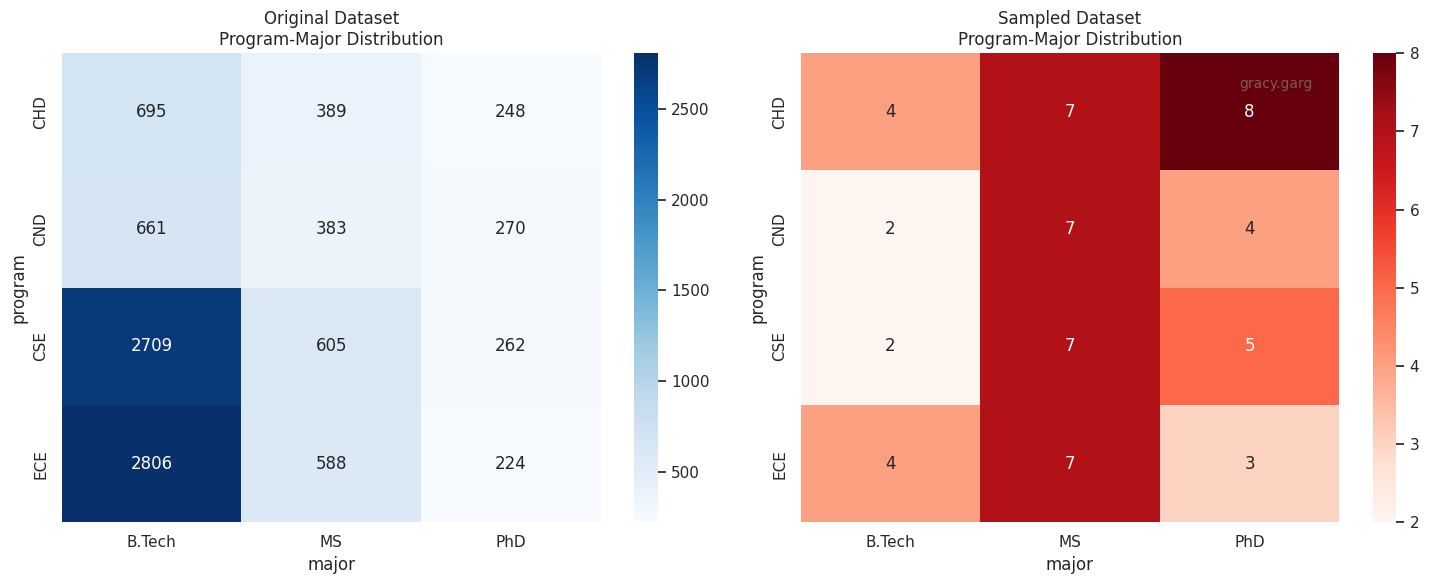

In [25]:
program_major_sample = advanced_analysis.sample_program_major_balanced(n=60)
advanced_analysis.show_program_major_counts_and_heatmap(program_major_sample)

### Q1.5 Analysis: Program-Major Balanced Sampling Strategy

The program-major balanced sampling achieves **perfect balance** across all valid program-major combinations:

1. The sample aimed for equal representation across all program-major combinations.
2. Most combinations have 4–8 students, but some (e.g., CND-B.Tech, CSE-B.Tech) have ~2, while others (CHD-PhD) have ~8.
3. This unevenness occurs because some groups in the original dataset are smaller, so it was not possible to sample the same number from every combination.
Overall, the strategy provides much more balanced representation than random sampling, but perfect balance is only possible if all groups are large enough.

**Were any groups too small? How did you handle it?**

In this dataset, all program-major combinations had enough students for balanced sampling (each group needed 5, and the smallest group had 227). However, the code is designed to handle small groups:

- If a group has fewer students than required, the code automatically takes all available students from that group (without replacement) and reports this in the output.
- This ensures no errors occur and the sample remains as balanced as possible, even if some combinations are rare or very small.
- In this run, no groups were too small, but the strategy guarantees graceful handling for any future datasets with rare combinations.

# > Save Data for other questions

In [26]:
df.to_csv("student_dataset.csv", index=False)